# Cash-advance underwriting: a synthetic end-to-end credit science pipeline

**What this notebook does.** It simulates a short-duration cash-advance business (bank-account cash flow in, a repayment outcome ~11 days later), then does the full credit-science loop on top of it:

| # | Section | Question it answers |
|---|---|---|
| 1 | Simulator | Can we generate cash-flow data with realistic rhythms (paydays, bills, shocks)? |
| 2 | Applications and outcomes | What are the labels, and how do they mature? |
| 3 | Point-in-time features | Are features built only from data available at application time? (with a leakage test that can actually fail) |
| 4 | Models | Scorecard vs gradient boosting, **out-of-time and out-of-member** evaluation, calibration |
| 5 | SHAP | What drives the model, globally and per applicant? |
| 6 | Policy | How do scores become approve/decline **and** an advance amount? Scored against ground truth |
| 7 | Reason codes | Adverse-action style reasons from SHAP, plus a perturbation test of those reasons |
| 8 | Selection bias | What happens when you only observe repayment for people you approved? |
| 9 | Monitoring | PSI, calibration, label delay, and a macro stress period |
| 10 | Robustness | Do the conclusions survive different generator assumptions? |

**Everything here is synthetic.** No real lender data is used. The point is to demonstrate *methodology* in a world where the true default probability of every applicant is known, so each technique can be graded against the truth. Results should never be read as how a real lender's portfolio would perform. Fee, recovery and default-rate settings are illustrative assumptions, not any company's actual numbers.

**Design choices worth knowing**
- Time-based splits: a burn-in (apply days up to 104, so history windows are complete), train (105-164), validation (165-184), then an embargo while labels mature, then an out-of-time test from day 235 on.
- 15% of members are never used for training (**out-of-member** test).
- A macro stress regime starts on day 300, after the model is frozen, to test monitoring.
- Defaults are drawn from a hidden, nonlinear, noisy probability, so the model has to *learn* the relationship from cash-flow features (it cannot read the rule off).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, time
import lightgbm as lgb, shap
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (7, 4)})
SEED = 7
RESULTS = {}      # collected headline numbers, printed at the end

CFG = dict(
    n_members=20000, n_days=360, warmup=60, burnin_end=104,   # applications up to burnin_end are burn-in (history windows incomplete)
    # time split (by application day)
    train_end=164, valid_end=184, test_start=235, stress_start=300,
    min_gap_days=3, label_lag=14,            # default = still unpaid 14 days after due date
    holdout_member_frac=0.15,                # members never used in training
    # hidden default process
    target_base_rate=0.04,                   # pre-stress default rate (illustrative)
    stress_logit=0.7, stress_shock_mult=1.8, stress_missed_pay_add=0.04,
    gig_share=0.30, shock_scale=1.0, eps_sd=1.4,
    # application behaviour
    req_rate_low=0.10, req_rate_base=0.008,
    # economics (illustrative assumptions, not any company's real terms)
    fee_rate=0.05, min_fee=5.0, recovery=0.30,
)

def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

## 1. The simulator

Each member gets hidden traits: pay frequency, income, income volatility (gig vs salaried), three monthly bills, spending habits and a hidden **fragility** score (how thin their buffer is). We then step day by day: paychecks arrive (with noise and occasional misses), bills hit on fixed days, discretionary spending is suppressed when the balance is low, and random shocks (car repair, lost shift) land. Falling below zero triggers an overdraft fee.

Daily arrays (`bal`, `dep`, `bil`, `spd`, `shk`, `odc`) play the role of a transaction feed.

In [2]:
def simulate(cfg, seed=SEED):
    rng = np.random.default_rng(seed)
    N, T = cfg["n_members"], cfg["n_days"]
    # ---- hidden traits
    period = rng.choice([7, 14, 30], size=N, p=[.20, .55, .25])
    phase = rng.integers(0, period)
    gig = rng.random(N) < cfg["gig_share"]
    monthly_income = np.exp(rng.normal(np.log(2600), 0.35, N)).clip(900, 9000)
    frag = rng.beta(2, 5, N)                                        # hidden fragility
    pay_pp = monthly_income * period / 30.0                         # pay per pay period
    pay_sd = np.where(gig, 0.30, 0.03)
    miss_p = np.where(gig, 0.07, 0.01)
    bill_frac = (0.45 + 0.40 * frag + rng.normal(0, 0.05, N)).clip(0.30, 0.95)
    split = rng.dirichlet([4, 2, 1.5], size=N)
    bill_days = np.sort(rng.integers(1, 29, (N, 3)), axis=1)
    bills_amt = bill_frac[:, None] * monthly_income[:, None] * split
    spend_mean = (1 - bill_frac).clip(0.05, None) * monthly_income * (0.70 + 0.50 * frag) / 30.0
    shock_rate = cfg["shock_scale"] * (0.004 + 0.010 * frag)

    bal = np.zeros((N, T), np.float32); dep = np.zeros((N, T), np.float32)
    bil = np.zeros((N, T), np.float32); spd = np.zeros((N, T), np.float32)
    shk = np.zeros((N, T), np.float32); odc = np.zeros((N, T), np.int8)
    b = monthly_income * rng.uniform(0.02, 0.25, N)

    for t in range(T):
        stress = t >= cfg["stress_start"]
        is_pay = ((t - phase) % period) == 0
        miss = rng.random(N) < (miss_p + (cfg["stress_missed_pay_add"] if stress else 0.0))
        pay = pay_pp * np.exp(rng.normal(0, pay_sd) - 0.5 * pay_sd ** 2)
        d = np.where(is_pay & ~miss, pay, 0.0)
        dom = (t % 30) + 1
        bsum = (bills_amt * (bill_days == dom)).sum(1)
        supp = np.where(b > 2000, 2.2, np.where(b > 1000, 1.5, np.where(b > 300, 1.0, np.where(b > 50, 0.6, np.where(b > 0, 0.35, 0.2)))))
        dow = 1.25 if (t % 7) in (4, 5) else 0.95
        s = spend_mean * supp * dow * rng.gamma(2.0, 0.5, N)
        sh_rate = shock_rate * (cfg["stress_shock_mult"] if stress else 1.0)
        sh = np.where(rng.random(N) < sh_rate, np.exp(rng.normal(np.log(220), 0.6, N)), 0.0)
        nb = b + d - bsum - s - sh
        cross = (b >= 0) & (nb < 0)
        nb = nb - np.where(cross, 15.0, 0.0)          # overdraft fee
        nb = np.maximum(nb, -400.0)                   # transactions get declined beyond this
        bal[:, t], dep[:, t], bil[:, t], spd[:, t], shk[:, t], odc[:, t] = nb, d, bsum, s, sh, cross
        b = nb
    return dict(N=N, T=T, bal=bal, dep=dep, bil=bil, spd=spd, shk=shk, odc=odc, period=period, phase=phase,
                gig=gig, monthly_income=monthly_income, frag=frag, pay_pp=pay_pp, shock_rate=shock_rate)

t0 = time.time()
S = simulate(CFG)
print(f"simulated {S['N']:,} members x {S['T']} days in {time.time()-t0:.1f}s")

simulated 20,000 members x 360 days in 2.3s


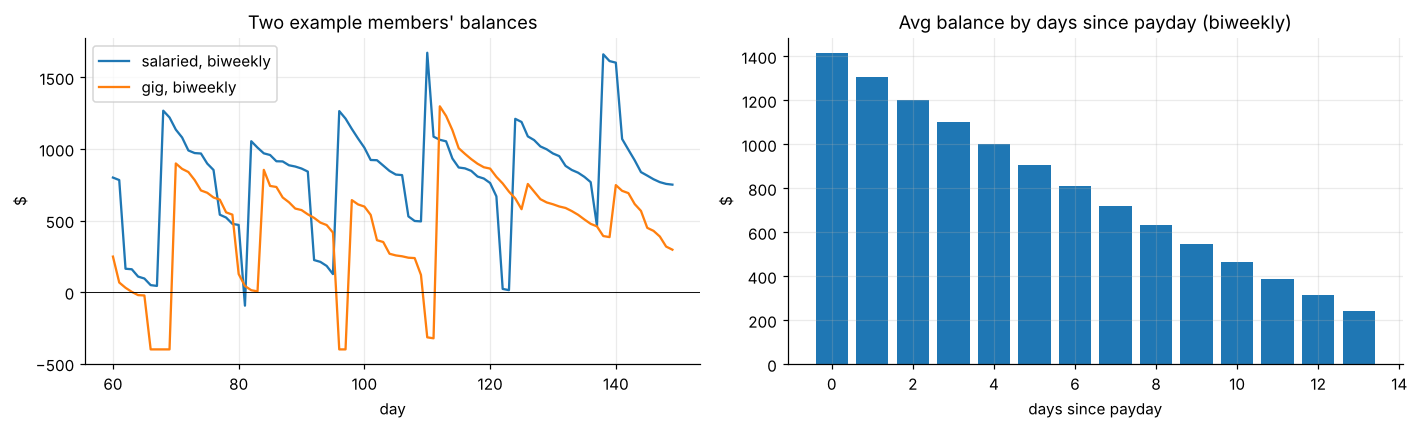

share of member-days with balance < $100: 15.4%   negative: 12.0%
overdraft events per member per 30 days: 0.63


In [3]:
# ---- stylized-fact checks: does the data look like cash-flow data?
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
g = np.flatnonzero(S["gig"] & (S["period"] == 14))[0]; s_ = np.flatnonzero(~S["gig"] & (S["period"] == 14))[0]
days = np.arange(60, 150)
ax[0].plot(days, S["bal"][s_, days], label="salaried, biweekly"); ax[0].plot(days, S["bal"][g, days], label="gig, biweekly")
ax[0].axhline(0, c="k", lw=.6); ax[0].set(title="Two example members' balances", xlabel="day", ylabel="$"); ax[0].legend()
# average balance by days since last scheduled payday (biweekly members): should dip before payday
m = S["period"] == 14
dsp = (np.arange(60, S["T"])[None, :] - S["phase"][m][:, None]) % 14
mean_by = [S["bal"][m][:, 60:][dsp == k].mean() for k in range(14)]
ax[1].bar(range(14), mean_by); ax[1].set(title="Avg balance by days since payday (biweekly)", xlabel="days since payday", ylabel="$")
plt.tight_layout(); plt.show()
print(f"share of member-days with balance < $100: {(S['bal'][:, 60:] < 100).mean():.1%}   negative: {(S['bal'][:, 60:] < 0).mean():.1%}")
print(f"overdraft events per member per 30 days: {S['odc'][:, 60:].sum(1).mean() / (S['T']-60) * 30:.2f}")

## 2. Applications and outcomes

Members request an advance when their balance is low, and only one advance can be open at a time. The advance is due on the member's **next payday at least 3 days out**, which gives an average term near 11 days. A default means *still unpaid 14 days after the due date*, so every label arrives `due_day + 14`, which is the **label delay**. The train/validation windows are chosen so that every training label has matured before the test period begins (asserted below).

**Hidden default process.** The true default probability is a nonlinear function of hidden fragility, gig status, advance size relative to a paycheck (convex), a U-shaped term in days-to-due, shock exposure over the loan window, balance at application, and a macro stress term, plus unobservable noise. The model never sees fragility or pay-per-period directly; it has to infer risk from cash-flow behaviour. An intercept is calibrated so the pre-stress base rate hits the target.

Simplification: the repayment outcome is *drawn* from that hidden probability rather than simulated through post-advance balances.

In [4]:
def make_applications(S, cfg, seed=SEED):
    rng = np.random.default_rng(seed + 1)
    N, T = S["N"], S["T"]
    bal, period, phase = S["bal"], S["period"], S["phase"]
    open_until = np.full(N, -1)
    out = []
    for t in range(cfg["warmup"], T):
        need = np.clip(150.0 - bal[:, t - 1], 0, None)
        p_req = np.where(need > 0, cfg["req_rate_low"] + 0.20 * np.minimum(need / 400.0, 1.0), cfg["req_rate_base"])
        idx = np.flatnonzero((open_until < t) & (rng.random(N) < p_req))
        if idx.size == 0: continue
        amt = np.clip(25 * np.round((need[idx] + rng.gamma(2.0, 45.0, idx.size)) / 25), 25, 500)
        g = cfg["min_gap_days"]
        due = t + g + ((phase[idx] - (t + g)) % period[idx])
        open_until[idx] = due
        out.append(pd.DataFrame({"member": idx, "apply_day": t, "amount": amt, "days_to_due": due - t, "due_day": due}))
    A = pd.concat(out, ignore_index=True)
    A["app_id"] = np.arange(len(A))
    A["label_day"] = A["due_day"] + cfg["label_lag"]
    mem = A["member"].values
    A["frag"] = S["frag"][mem]; A["gig"] = S["gig"][mem].astype(float)
    A["pay_pp"] = S["pay_pp"][mem]; A["shock_rate"] = S["shock_rate"][mem]
    A["bal_app"] = S["bal"][mem, A["apply_day"].values - 1].astype(float)
    return A

def true_core(frag, gig, pay_pp, shock_rate, dtd, bal_app, amount, stress_flag, cfg):
    ratio = amount / pay_pp
    return (2.2 * (frag - 0.25) + 0.45 * gig
            + 3.0 * ratio ** 1.4 + 1.2 * gig * ratio
            + 0.015 * (dtd - 10.0) ** 2 / 10.0
            + 5.0 * shock_rate * dtd
            + 0.9 * np.clip(-bal_app, 0, 400) / 400 - 0.3 * np.clip(bal_app, 0, 600) / 600
            + cfg["stress_logit"] * stress_flag)

def true_pd_from_core(z, cfg): return sigmoid(z / np.sqrt(1 + np.pi * cfg["eps_sd"] ** 2 / 8))   # E over the noise term (probit approx.)

def assign_outcomes(A, cfg, seed=SEED):
    rng = np.random.default_rng(seed + 2)
    stress_flag = (A["apply_day"].values >= cfg["stress_start"]).astype(float)
    core = true_core(A.frag.values, A.gig.values, A.pay_pp.values, A.shock_rate.values, A.days_to_due.values,
                     A.bal_app.values, A.amount.values, stress_flag, cfg)
    pre = A["apply_day"].values < cfg["stress_start"]
    lo, hi = -14.0, 4.0
    for _ in range(60):
        mid = (lo + hi) / 2
        if true_pd_from_core(core[pre] + mid, cfg).mean() > cfg["target_base_rate"]: hi = mid
        else: lo = mid
    icpt = (lo + hi) / 2
    A["true_pd"] = true_pd_from_core(core + icpt, cfg)
    A["default"] = (rng.random(len(A)) < sigmoid(core + icpt + rng.normal(0, cfg["eps_sd"], len(A)))).astype(int)
    return A, icpt

def true_pd_at(A, amounts, icpt, cfg):
    # ground-truth default probability if each applicant in A were offered `amounts` instead
    stress_flag = (A["apply_day"].values >= cfg["stress_start"]).astype(float)
    core = true_core(A.frag.values, A.gig.values, A.pay_pp.values, A.shock_rate.values, A.days_to_due.values,
                     A.bal_app.values, amounts, stress_flag, cfg)
    return true_pd_from_core(core + icpt, cfg)

def add_history(A, window=45):
    # advances in the last `window` days, and how many of those are KNOWN defaults (label already matured) at application time
    A = A.sort_values(["member", "apply_day"]).reset_index(drop=True)
    prior = A[["member", "app_id", "apply_day", "label_day", "default"]].rename(
        columns={"app_id": "prior_id", "apply_day": "p_day", "label_day": "p_label", "default": "p_def"})
    m = A[["member", "app_id", "apply_day"]].merge(prior, on="member")
    m = m[(m.prior_id != m.app_id) & (m.p_day < m.apply_day) & (m.apply_day - m.p_day <= window)]
    A["n_adv_45d"] = A["app_id"].map(m.groupby("app_id").size()).fillna(0.0)
    known = m[m.p_label <= m.apply_day]                                    # only outcomes already known at application time
    A["known_defaults_45d"] = A["app_id"].map(known.groupby("app_id")["p_def"].sum()).fillna(0.0)
    return A

def assign_splits(A, S, cfg, seed=SEED):
    rng = np.random.default_rng(seed + 3)
    hold = rng.random(S["N"]) < cfg["holdout_member_frac"]
    A["holdout"] = hold[A["member"].values]
    d, h = A["apply_day"].values, A["holdout"].values
    A["split"] = np.select([(d > cfg["burnin_end"]) & (d <= cfg["train_end"]) & ~h,
                            (d > cfg["train_end"]) & (d <= cfg["valid_end"]) & ~h,
                            d >= cfg["test_start"]], ["train", "valid", "test"], default="unused")
    A["regime"] = np.where(d >= cfg["stress_start"], "stress", "normal")
    # label-maturity assertion: nothing used for training/validation may have a label arriving after the test window opens
    assert A.loc[A.split.isin(["train", "valid"]), "label_day"].max() <= cfg["test_start"], "label leakage across split"
    return A

In [5]:
def build_features(S, A, lag=1):
    # Everything is computed from days strictly BEFORE the application day (lag=1).
    # lag=0 is deliberately leaky and exists only to prove the leakage test can fail.
    mi, d = A["member"].values, A["apply_day"].values
    cols = d[:, None] - np.arange(lag, lag + 60)[None, :]
    assert cols.min() >= 0
    g = lambda k: S[k][mi[:, None], cols].astype(np.float64)
    B, D, BL, SP, SH, OD = g("bal"), g("dep"), g("bil"), g("spd"), g("shk"), g("odc")
    f = {}
    f["bal_now"] = B[:, 0]
    f["bal_min_7"] = B[:, :7].min(1); f["bal_min_30"] = B[:, :30].min(1)
    f["bal_mean_30"] = B[:, :30].mean(1); f["bal_std_30"] = B[:, :30].std(1)
    f["neg_days_30"] = (B[:, :30] < 0).sum(1); f["low_days_30"] = (B[:, :30] < 100).sum(1)
    f["od_events_30"] = OD[:, :30].sum(1); f["od_events_60"] = OD.sum(1)
    dep30, dep60 = D[:, :30].sum(1), D.sum(1)
    f["income_30"] = dep30; f["income_60_monthly"] = dep60 / 2.0
    n30, n60 = (D[:, :30] > 0).sum(1), (D > 0).sum(1)
    f["n_deposits_30"] = n30; f["n_deposits_60"] = n60
    Dm = np.where(D > 0, D, np.nan)
    with np.errstate(all="ignore"):
        f["dep_cv"] = np.nanstd(Dm, 1) / np.nanmean(Dm, 1)
    has = D > 0
    dsd = np.where(has.any(1), has.argmax(1) + 1, 61)
    f["days_since_dep"] = dsd
    est_period = np.clip(60.0 / np.maximum(n60, 1), 5, 60)
    f["est_days_to_next_dep"] = np.clip(est_period - dsd, 0, None)
    bills30 = BL[:, :30].sum(1)
    f["bills_30"] = bills30; f["bills_to_income"] = bills30 / np.maximum(dep30, 100.0)
    sp30 = (SP + SH)[:, :30].sum(1)
    f["spend_30"] = sp30; f["spend_to_income"] = sp30 / np.maximum(dep30, 100.0)
    f["n_large_outflows_60"] = ((SP + SH) > 150).sum(1)
    f["amount"] = A["amount"].values
    f["amount_to_income"] = A["amount"].values / np.maximum(dep30, 100.0)
    f["days_to_due"] = A["days_to_due"].values
    f["n_adv_45d"] = A["n_adv_45d"].values; f["known_defaults_45d"] = A["known_defaults_45d"].values
    return pd.DataFrame(f).astype("float32")

def leakage_test(S, A, X, lag=1, n_check=300, seed=0):
    # Corrupt EVERYTHING from the application day onward for a sample of applications and rebuild their features.
    # If any feature changes, it was peeking at the present or the future.
    rng = np.random.default_rng(seed)
    pick = rng.choice(len(A), n_check, replace=False)
    sub = A.iloc[pick].reset_index(drop=True)
    S2 = dict(S)
    for k in ["bal", "dep", "bil", "spd", "shk", "odc"]:
        rows = S[k][sub["member"].values].copy()
        for i, d in enumerate(sub["apply_day"].values):
            rows[i, d:] = rng.integers(0, 5, rows.shape[1] - d) if k == "odc" else rng.normal(5000, 3000, rows.shape[1] - d)
        S2[k] = rows
    sub2 = sub.copy(); sub2["member"] = np.arange(n_check)
    X2 = build_features(S2, sub2, lag=lag)
    X1 = build_features(S, sub, lag=lag) if lag == 0 else X.iloc[pick].reset_index(drop=True)
    diff = (X1.fillna(-999) - X2.fillna(-999)).abs().max()
    return diff[diff > 1e-4]

def generate_world(cfg, seed=SEED):
    S = simulate(cfg, seed)
    A = make_applications(S, cfg, seed)
    A, icpt = assign_outcomes(A, cfg, seed)
    A = add_history(A)
    A = assign_splits(A, S, cfg, seed)
    X = build_features(S, A)
    return S, A, X, icpt

t0 = time.time()
S, A, X, ICPT = generate_world(CFG)
FEATURES = list(X.columns)
print(f"{len(A):,} applications, {len(FEATURES)} features, built in {time.time()-t0:.1f}s")

126,592 applications, 26 features, built in 3.7s


In [6]:
# ---- leakage test: the real features must pass, and a deliberately leaky version must FAIL
bad = leakage_test(S, A, X, lag=1)
leaky = leakage_test(S, A, X, lag=0)
print("point-in-time features (lag=1): features that changed when the present/future was corrupted ->", len(bad), "(want 0)")
print("deliberately leaky features (lag=0): features that changed ->", len(leaky), "(want > 0, proves the test has teeth)")
assert len(bad) == 0 and len(leaky) > 0
RESULTS["leakage_test"] = f"lag=1 changed {len(bad)} features; lag=0 changed {len(leaky)}"

point-in-time features (lag=1): features that changed when the present/future was corrupted -> 0 (want 0)
deliberately leaky features (lag=0): features that changed -> 22 (want > 0, proves the test has teeth)


,apps,default_rate,mean_true_pd,avg_amount,avg_days_to_due,pct_of_apps
split,,,,,,
test,52819,0.047,0.054,284.033,10.633,0.417
train,20878,0.034,0.040,277.857,10.672,0.165
unused,46488,0.036,0.041,285.068,10.666,0.367
valid,6407,0.030,0.037,263.825,10.850,0.051


,apps,default_rate,mean_true_pd
regime,,,
normal,25545,0.035,0.039
stress,27274,0.059,0.067


apps per member (mean): 6.3   avg term: 10.7 days   share of members ever applying: 99%


ORACLE AUC (ranking by the true hidden probability) on test: 0.821  <- ceiling for any model


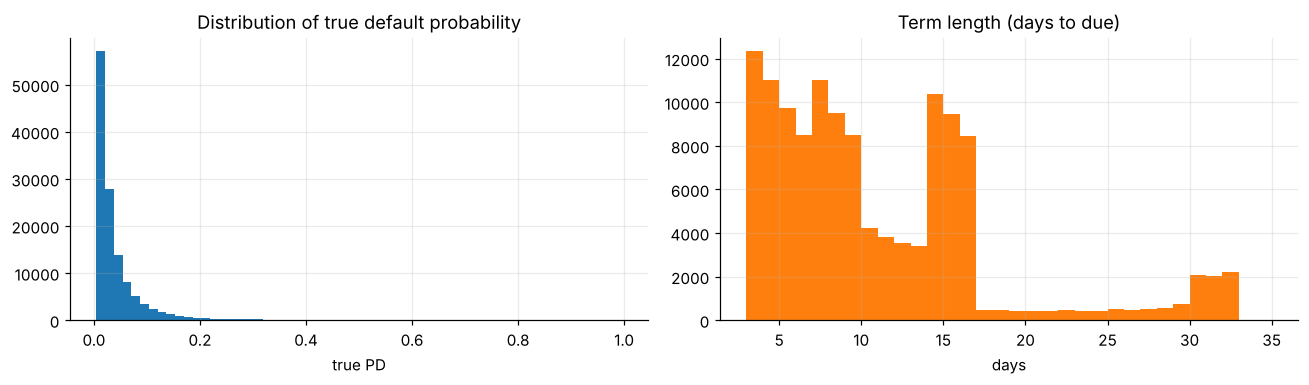

In [7]:
# ---- what the generated portfolio looks like
sp = A.groupby("split").agg(apps=("app_id", "size"), default_rate=("default", "mean"), mean_true_pd=("true_pd", "mean"),
                            avg_amount=("amount", "mean"), avg_days_to_due=("days_to_due", "mean"))
sp["pct_of_apps"] = sp.apps / sp.apps.sum()
reg = A[A.split == "test"].groupby("regime").agg(apps=("app_id", "size"), default_rate=("default", "mean"), mean_true_pd=("true_pd", "mean"))
display(sp); display(reg)
print(f"apps per member (mean): {len(A)/S['N']:.1f}   avg term: {A.days_to_due.mean():.1f} days   share of members ever applying: {A.member.nunique()/S['N']:.0%}")
oracle_auc = roc_auc_score(A.loc[A.split == 'test', 'default'], A.loc[A.split == 'test', 'true_pd'])
print(f"ORACLE AUC (ranking by the true hidden probability) on test: {oracle_auc:.3f}  <- ceiling for any model")
RESULTS["oracle_auc_test"] = oracle_auc
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(A.true_pd, bins=60, color="C0"); ax[0].set(title="Distribution of true default probability", xlabel="true PD")
ax[1].hist(A.days_to_due, bins=range(3, 36), color="C1"); ax[1].set(title="Term length (days to due)", xlabel="days")
plt.tight_layout(); plt.show()

## 3-4. Models and out-of-sample evaluation

Two models:

1. **Scorecard baseline**: quantile-binned features into a logistic regression (the classic scorecard shape).
2. **LightGBM** with monotonic constraints on features where direction is unambiguous (more overdrafts means more risk, more income means less). `days_to_due` and a few others are left unconstrained because the true relationship is U-shaped. An unconstrained version shows what the constraints cost.

**Evaluation sets** (none touched during training or early stopping):
- *valid*: later applications by training members, used only for early stopping and calibration.
- *test, normal*: out-of-time (day 235+, before the stress regime), all members.
- *test, unseen members*: out-of-time **and** members the model has never seen.
- *test, stress*: after the macro shock begins, the model frozen.

Probabilities are Platt-calibrated on the validation set.

In [8]:
LGB_PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=7, min_data_in_leaf=400, feature_fraction=0.7,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=30.0, verbose=-1, seed=SEED, num_threads=2)
MONO = {"od_events_30": 1, "od_events_60": 1, "neg_days_30": 1, "bills_to_income": 1, "spend_to_income": 1,
        "amount": 1, "amount_to_income": 1, "bal_now": -1, "income_30": -1, "known_defaults_45d": 1}

def train_lgb(Xtr, ytr, Xva, yva, wtr=None, wva=None, mono=True, rounds=3000):
    p = dict(LGB_PARAMS)
    if mono: p["monotone_constraints"] = [MONO.get(c, 0) for c in Xtr.columns]
    dtr = lgb.Dataset(Xtr, ytr, weight=wtr)
    dva = lgb.Dataset(Xva, yva, weight=wva, reference=dtr)
    return lgb.train(p, dtr, rounds, valid_sets=[dva], callbacks=[lgb.early_stopping(100, verbose=False)])

def raw_pd(b, Xd): return b.predict(Xd, num_iteration=b.best_iteration)

def make_scorecard():
    return make_pipeline(SimpleImputer(strategy="median"),
                         KBinsDiscretizer(n_bins=6, encode="onehot-dense", strategy="quantile"),
                         LogisticRegression(C=0.3, max_iter=3000))

def ks_stat(y, p): return ks_2samp(p[y == 1], p[y == 0]).statistic

def ece(y, p, bins=10):
    q = pd.qcut(p, bins, duplicates="drop"); g = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True)
    return float(np.average(np.abs(g.y.mean() - g.p.mean()), weights=g.size()))

def metrics(y, p):
    return dict(n=len(y), base_rate=y.mean(), mean_pred=p.mean(), AUC=roc_auc_score(y, p), KS=ks_stat(y, p),
                Brier=brier_score_loss(y, p), ECE=ece(y, p))

M = {s: (A.split == s).values for s in ["train", "valid"]}
Xtr, ytr, Xva, yva = X[M["train"]], A.default[M["train"]].values, X[M["valid"]], A.default[M["valid"]].values

t0 = time.time()
BOOST = train_lgb(Xtr, ytr, Xva, yva, mono=True)
BOOST_FREE = train_lgb(Xtr, ytr, Xva, yva, mono=False)
SC = make_scorecard().fit(Xtr, ytr)
print(f"trained in {time.time()-t0:.0f}s; LightGBM rounds: constrained={BOOST.best_iteration}, unconstrained={BOOST_FREE.best_iteration}")

# Platt calibration on the validation set only
CAL = LogisticRegression(C=1e6).fit(logit(raw_pd(BOOST, Xva)).reshape(-1, 1), yva)
def cal_pd(b, Xd): return CAL.predict_proba(logit(raw_pd(b, Xd)).reshape(-1, 1))[:, 1]

trained in 2s; LightGBM rounds: constrained=431, unconstrained=234


In [9]:
test = (A.split == "test").values
EVAL = {"train": M["train"], "valid": M["valid"],
        "test normal (out-of-time)": test & (A.regime == "normal").values,
        "test normal, unseen members": test & (A.regime == "normal").values & A.holdout.values,
        "test stress": test & (A.regime == "stress").values}
rows = []
for name, m in EVAL.items():
    y = A.default[m].values; Xm = X[m]
    for mname, p in [("scorecard", SC.predict_proba(Xm)[:, 1]), ("LGBM unconstrained", raw_pd(BOOST_FREE, Xm)),
                     ("LGBM monotone", raw_pd(BOOST, Xm)), ("LGBM monotone + Platt", cal_pd(BOOST, Xm)),
                     ("ORACLE (true PD)", A.true_pd[m].values)]:
        rows.append({"set": name, "model": mname, **metrics(y, p)})
R = pd.DataFrame(rows)
display(R.pivot(index="set", columns="model", values="AUC")[["scorecard", "LGBM unconstrained", "LGBM monotone", "ORACLE (true PD)"]].loc[list(EVAL)])
print("KS, Brier, ECE for the calibrated LightGBM and the scorecard:")
display(R[R.model.isin(["scorecard", "LGBM monotone + Platt"])].set_index(["set", "model"])[["n", "base_rate", "mean_pred", "AUC", "KS", "Brier", "ECE"]])
RESULTS["auc_table"] = R.pivot(index="set", columns="model", values="AUC")

model,scorecard,LGBM unconstrained,LGBM monotone,ORACLE (true PD)
set,,,,
train,0.816,0.841,0.852,0.824
valid,0.792,0.806,0.807,0.831
test normal (out-of-time),0.779,0.792,0.788,0.810
"test normal, unseen members",0.736,0.762,0.761,0.785
test stress,0.782,0.794,0.792,0.817


KS, Brier, ECE for the calibrated LightGBM and the scorecard:


n  base_rate  mean_pred   AUC    KS  Brier   ECE
set                         model                                                                      
train                       scorecard              20878      0.034      0.034 0.816 0.487  0.029 0.004
                            LGBM monotone + Platt  20878      0.034      0.033 0.852 0.533  0.028 0.006
valid                       scorecard               6407      0.030      0.032 0.792 0.476  0.027 0.006
                            LGBM monotone + Platt   6407      0.030      0.030 0.807 0.496  0.027 0.003
test normal (out-of-time)   scorecard              25545      0.035      0.033 0.779 0.451  0.030 0.004
                            LGBM monotone + Platt  25545      0.035      0.031 0.788 0.442  0.030 0.003
test normal, unseen members scorecard               3781      0.037      0.032 0.736 0.390  0.033 0.009
                            LGBM monotone + Platt   3781      0.037      0.030 0.761 0.394  0.033 0.008
test stress                 scorecard              27274      0.059      0.038 0.782 0.426  0.051 0.021
                            LGBM monotone + Platt  27274      0.059      0.038 0.792 0.441  0.050 0.021

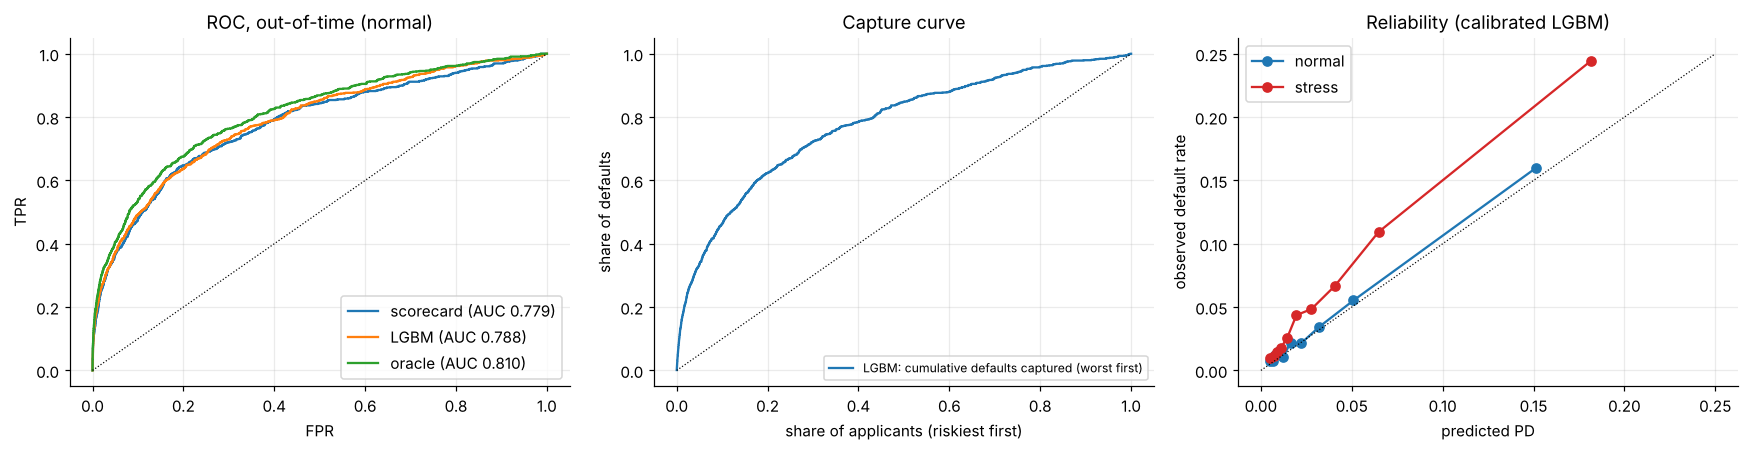

In [10]:
mn = EVAL["test normal (out-of-time)"]; ms = EVAL["test stress"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
y = A.default[mn].values
for nm, p in [("scorecard", SC.predict_proba(X[mn])[:, 1]), ("LGBM", cal_pd(BOOST, X[mn])), ("oracle", A.true_pd[mn].values)]:
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f"{nm} (AUC {roc_auc_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=.8); ax[0].set(title="ROC, out-of-time (normal)", xlabel="FPR", ylabel="TPR"); ax[0].legend(loc="lower right")
p = cal_pd(BOOST, X[mn]); o = np.argsort(p); n = len(o)
ax[1].plot(np.arange(1, n + 1) / n, np.cumsum(y[o][::-1]) / y.sum(), label="LGBM: cumulative defaults captured (worst first)")
ax[1].plot([0, 1], [0, 1], "k:", lw=.8); ax[1].set(title="Capture curve", xlabel="share of applicants (riskiest first)", ylabel="share of defaults"); ax[1].legend(loc="lower right", fontsize=8)
for lab, m, c in [("normal", mn, "C0"), ("stress", ms, "C3")]:
    pp, yy = cal_pd(BOOST, X[m]), A.default[m].values
    q = pd.qcut(pp, 10, duplicates="drop"); g = pd.DataFrame({"p": pp, "y": yy, "q": q}).groupby("q", observed=True)[["p", "y"]].mean()
    ax[2].plot(g.p, g.y, "o-", c=c, label=lab)
mx = 0.25; ax[2].plot([0, mx], [0, mx], "k:", lw=.8); ax[2].set(title="Reliability (calibrated LGBM)", xlabel="predicted PD", ylabel="observed default rate"); ax[2].legend()
plt.tight_layout(); plt.show()

## 5. SHAP: what drives the model

`TreeExplainer` with an **interventional** background (a sample of training applicants) gives each feature's contribution to the **log-odds** of default relative to that background. We check additivity (base value + sum of SHAP values = model output), then look at global importance, direction and shape, and a single applicant.

In [11]:
rng_s = np.random.default_rng(0)
BG = Xtr.sample(100, random_state=0)
te_idx = np.flatnonzero(mn); samp_idx = rng_s.choice(te_idx, 1500, replace=False)
Xs = X.iloc[samp_idx]; ys = A.default.iloc[samp_idx].values

t0 = time.time()
EXPL = shap.TreeExplainer(BOOST, BG, feature_perturbation="interventional")
SV = EXPL.shap_values(Xs)
if isinstance(SV, list): SV = SV[1]
SV = np.asarray(SV)
if SV.ndim == 3: SV = SV[:, :, 1]
BASE = float(np.ravel(EXPL.expected_value)[-1])
raw_out = BOOST.predict(Xs, num_iteration=BOOST.best_iteration, raw_score=True)
err = np.abs(SV.sum(1) + BASE - raw_out).max()
print(f"SHAP computed on {len(Xs)} out-of-time applicants in {time.time()-t0:.0f}s; max additivity error = {err:.2e}")
assert err < 1e-2

SHAP computed on 1500 out-of-time applicants in 12s; max additivity error = 9.83e-08


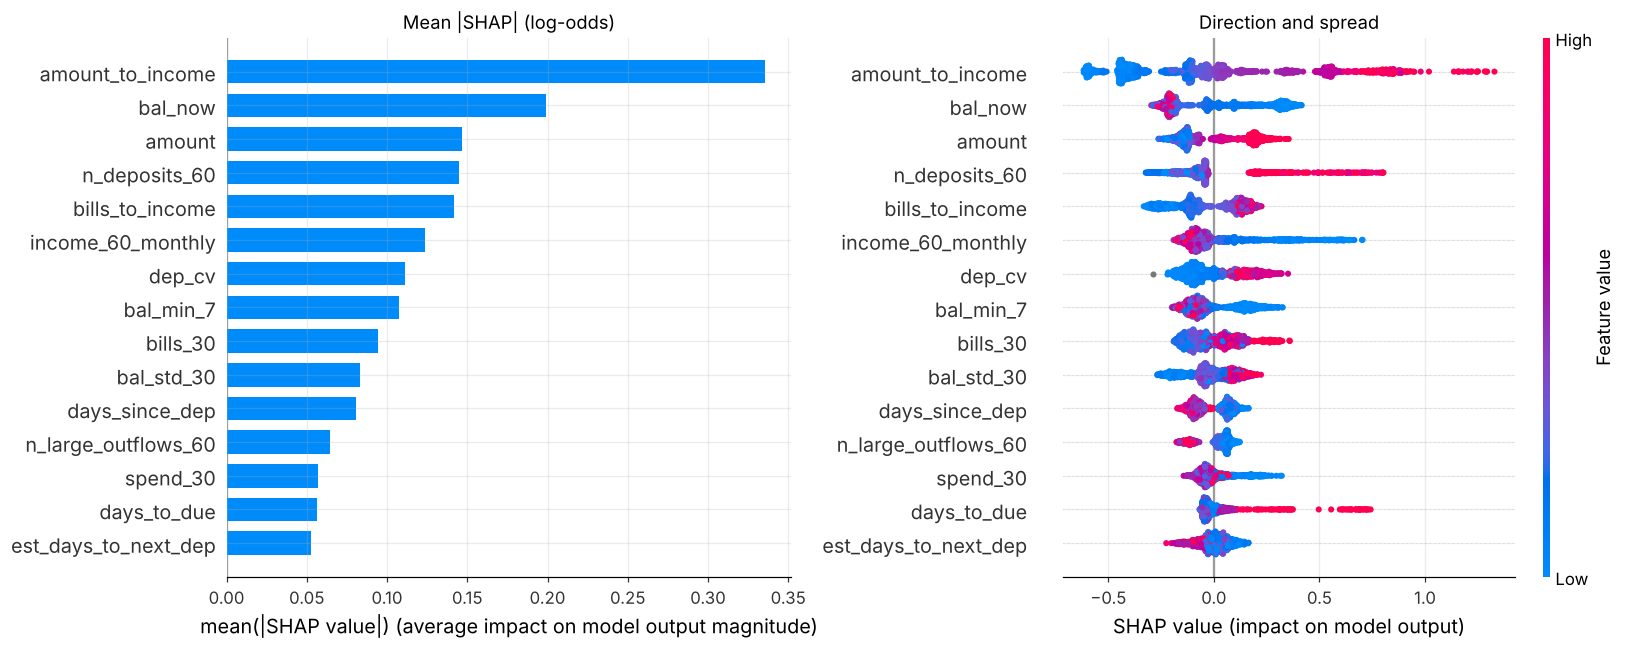

,mean |SHAP|
amount_to_income,0.335
bal_now,0.199
amount,0.147
n_deposits_60,0.145
bills_to_income,0.141
income_60_monthly,0.124
dep_cv,0.111
bal_min_7,0.108
bills_30,0.094
bal_std_30,0.083


In [12]:
imp = pd.Series(np.abs(SV).mean(0), index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
plt.sca(ax[0]); shap.summary_plot(SV, Xs, plot_type="bar", max_display=15, show=False, plot_size=None); ax[0].set_title("Mean |SHAP| (log-odds)")
plt.sca(ax[1]); shap.summary_plot(SV, Xs, max_display=15, show=False, plot_size=None); ax[1].set_title("Direction and spread")
plt.tight_layout(); plt.show()
display(imp.head(10).to_frame("mean |SHAP|"))

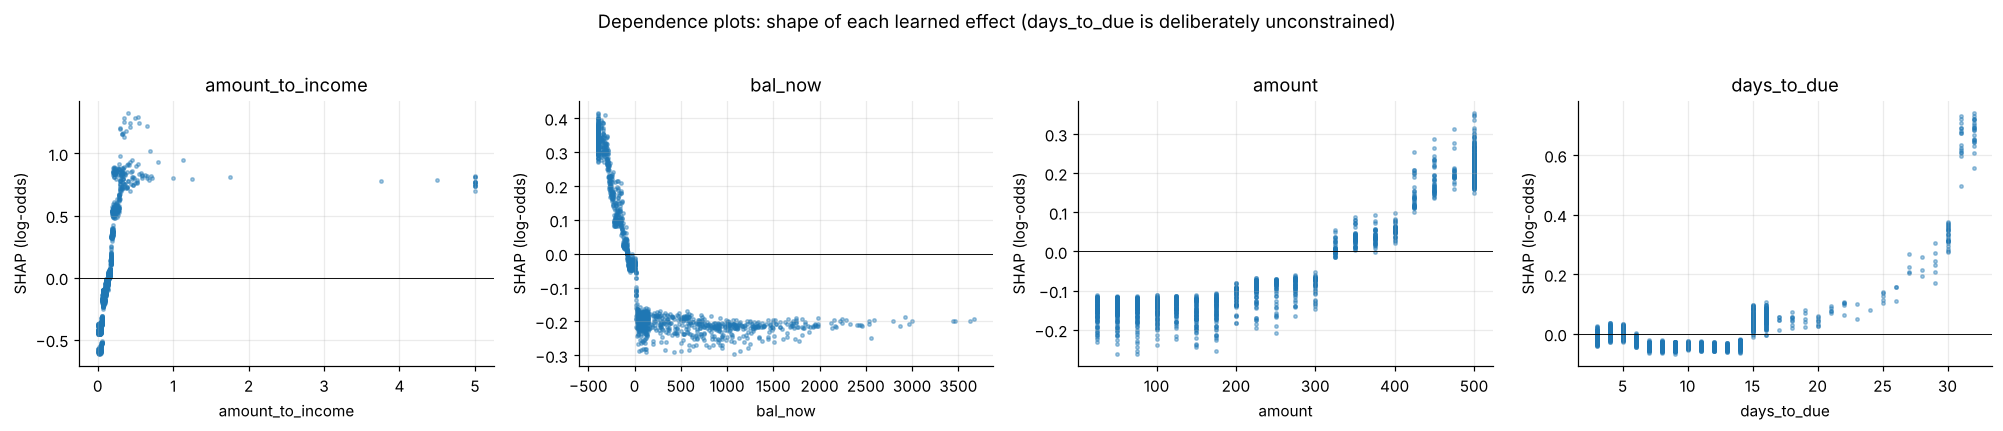

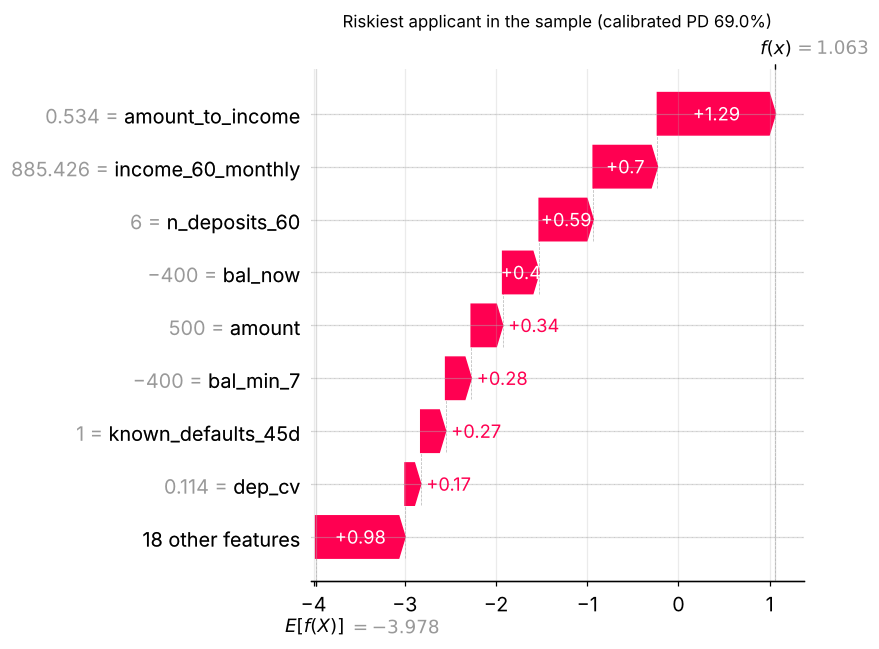

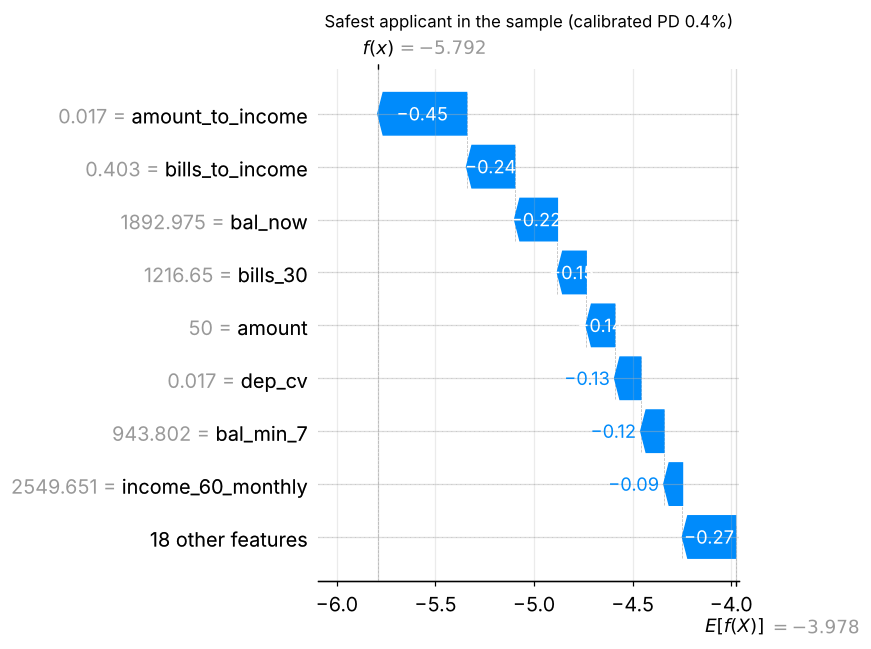

In [13]:
top = list(imp.index[:3]) + ["days_to_due"]
top = list(dict.fromkeys(top))[:4]
fig, ax = plt.subplots(1, len(top), figsize=(4.6 * len(top), 3.8))
for a, f in zip(np.atleast_1d(ax), top):
    j = FEATURES.index(f)
    a.scatter(Xs[f], SV[:, j], s=5, alpha=.4); a.axhline(0, c="k", lw=.6); a.set(xlabel=f, ylabel="SHAP (log-odds)", title=f)
plt.suptitle("Dependence plots: shape of each learned effect (days_to_due is deliberately unconstrained)", y=1.02)
plt.tight_layout(); plt.show()

# local explanation: riskiest vs safest applicant in the sample
pr = cal_pd(BOOST, Xs); hi_i, lo_i = int(pr.argmax()), int(pr.argmin())
for i, ttl in [(hi_i, f"Riskiest applicant in the sample (calibrated PD {pr[hi_i]:.1%})"), (lo_i, f"Safest applicant in the sample (calibrated PD {pr[lo_i]:.1%})")]:
    plt.figure(figsize=(9, 4.8))
    shap.plots.waterfall(shap.Explanation(values=SV[i], base_values=BASE, data=Xs.iloc[i].values, feature_names=FEATURES), max_display=9, show=False)
    plt.title(ttl, fontsize=11); plt.tight_layout(); plt.show()

**How to read these.** SHAP explains what the *model* learned, not what *causes* default. Example: `n_deposits_60` shows up as a risk driver even though more deposits is not risky in itself; in this world it proxies for pay-per-period (weekly payers get small paychecks, so the same advance is a larger share of a paycheck). The dependence plots also show the learned shapes: a steep rise then plateau in `amount_to_income`, a floor then a rise in `bal_now` below zero, and the unconstrained U-ish shape in `days_to_due`. The `f(x)` in the waterfalls is the raw model log-odds; the titles show the calibrated probability.

## 6. From score to decision: the policy layer

A model gives a probability; a **policy** turns it into approve/decline *and an amount*. For each applicant we re-score the model at every advance size from \$25 to \$500 (changing `amount` and `amount_to_income`), compute expected profit

`E[profit(a)] = (1 - PD(a)) * fee(a) - PD(a) * (1 - recovery) * a`

and pick the best amount subject to guardrails (no more than the requested amount, PD cap, and an income-based exposure cap). Decline if no amount has positive expected profit.

Because this is a simulation we can grade every policy against the **true** hidden default probability (which also depends on the amount). That gives *expected* profit with no sampling noise, which real data can never provide.

In [14]:
AMTS = np.arange(25, 501, 25).astype(float)
FEE = lambda a: np.maximum(CFG["min_fee"], CFG["fee_rate"] * a)
PD_CAP, EXPOSURE_CAP = 0.15, 0.30          # guardrails: max PD allowed, max advance as share of 30-day income

def pd_matrix_model(Xb):
    inc = np.maximum(Xb["income_30"].values, 100.0); M_ = np.zeros((len(Xb), len(AMTS)))
    for k, a in enumerate(AMTS):
        Xa = Xb.copy(); Xa["amount"] = np.float32(a); Xa["amount_to_income"] = (a / inc).astype(np.float32)
        M_[:, k] = cal_pd(BOOST, Xa)
    return M_

def pd_matrix_true(Ab):
    return np.column_stack([true_pd_at(Ab, np.full(len(Ab), a), ICPT, CFG) for a in AMTS])

def choose_amounts(PD, requested, income, cap_frac=EXPOSURE_CAP, pd_cap=PD_CAP):
    EP = (1 - PD) * FEE(AMTS)[None, :] - PD * (1 - CFG["recovery"]) * AMTS[None, :]
    ok = (AMTS[None, :] <= requested[:, None]) & (PD <= pd_cap) & (AMTS[None, :] <= cap_frac * np.maximum(income, 0)[:, None])
    EPm = np.where(ok, EP, -np.inf); k = EPm.argmax(1); best = EPm[np.arange(len(k)), k]
    return np.where(best > 0, AMTS[k], 0.0)

def score_policy(Ab, amount_given, icpt=ICPT):
    pdt = true_pd_at(Ab, np.where(amount_given > 0, amount_given, 1.0), icpt, CFG)
    ap = amount_given > 0; a = amount_given
    profit = np.where(ap, (1 - pdt) * FEE(a) - pdt * (1 - CFG["recovery"]) * a, 0.0)
    orig = a[ap].sum()
    return dict(approval_rate=ap.mean(), avg_amount_approved=a[ap].mean() if ap.any() else 0.0, originations=orig,
                exp_loss_rate=(pdt[ap] * (1 - CFG["recovery"]) * a[ap]).sum() / max(orig, 1), exp_profit=profit.sum(),
                profit_per_app=profit.mean())

def legacy_rule(Xb):
    return ((Xb.bal_now > -50) & (Xb.od_events_30 <= 2) & (Xb.income_30 >= 1000) & (Xb.amount_to_income <= 0.40)).values

def run_policies(mask):
    Ab, Xb = A[mask].reset_index(drop=True), X[mask].reset_index(drop=True)
    req, inc = Ab.amount.values, Xb.income_30.values
    PDm, PDt = pd_matrix_model(Xb), pd_matrix_true(Ab)
    pd_req = cal_pd(BOOST, Xb)                                    # model PD at the requested amount
    out = {"approve everyone (as requested)": req,
           "legacy rules (as requested)": np.where(legacy_rule(Xb), req, 0.0),
           "model, fixed 6% PD cutoff": np.where(pd_req <= 0.06, req, 0.0),
           "model + amount optimisation": choose_amounts(PDm, req, inc),
           "ORACLE (true PD) + optimisation": choose_amounts(PDt, req, inc)}
    return pd.DataFrame({k: score_policy(Ab, v) for k, v in out.items()}).T, out, Ab, Xb, PDm, PDt

POL_N, POL_OUT, A_pn, X_pn, PDm_pn, PDt_pn = run_policies(EVAL["test normal (out-of-time)"])
POL_S, *_ = run_policies(EVAL["test stress"])
print("Expected profit under the TRUE default probabilities, out-of-time, NORMAL regime"); display(POL_N)
print("Same policies, STRESS regime (model frozen)"); display(POL_S)
RESULTS["policy_normal"] = POL_N; RESULTS["policy_stress"] = POL_S

Expected profit under the TRUE default probabilities, out-of-time, NORMAL regime


,approval_rate,avg_amount_approved,originations,exp_loss_rate,exp_profit,profit_per_app
approve everyone (as requested),1.000,274.255,"7,005,850.000",0.039,"66,633.618",2.608
legacy rules (as requested),0.536,134.318,"1,838,950.000",0.014,"76,309.221",2.987
"model, fixed 6% PD cutoff",0.882,247.776,"5,584,875.000",0.023,"153,314.809",6.002
model + amount optimisation,0.988,213.062,"5,376,400.000",0.023,"169,232.548",6.625
ORACLE (true PD) + optimisation,0.987,189.631,"4,782,500.000",0.018,"184,076.349",7.206


Same policies, STRESS regime (model frozen)


,approval_rate,avg_amount_approved,originations,exp_loss_rate,exp_profit,profit_per_app
approve everyone (as requested),1.000,293.190,"7,996,475.000",0.065,"-147,240.195",-5.399
legacy rules (as requested),0.480,138.248,"1,808,150.000",0.023,"56,425.358",2.069
"model, fixed 6% PD cutoff",0.840,258.728,"5,929,000.000",0.038,"64,857.874",2.378
model + amount optimisation,0.974,215.211,"5,719,025.000",0.037,"90,778.810",3.328
ORACLE (true PD) + optimisation,0.970,129.551,"3,427,275.000",0.023,"145,323.759",5.328


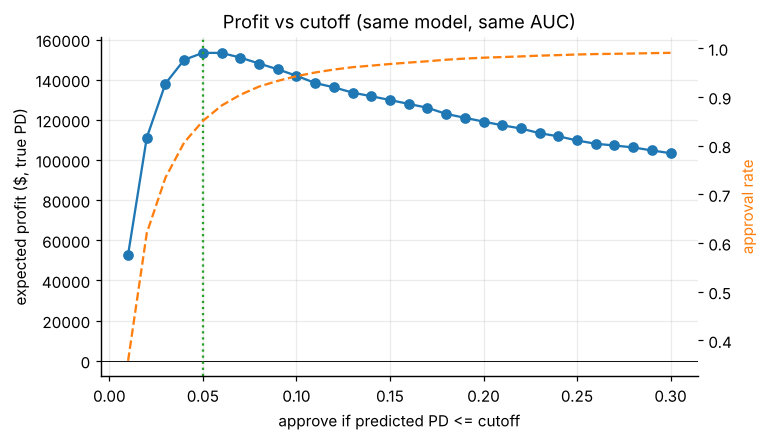

profit-maximising cutoff ~ 5% (approval 85%, expected profit 153,369); a fixed 6% cutoff earns 153,315


In [15]:
# AUC alone does not set the policy: sweep the cutoff and look at true expected profit
Ab, Xb = A_pn, X_pn
req = Ab.amount.values; pdh = cal_pd(BOOST, Xb)
pdt_req = true_pd_at(Ab, req, ICPT, CFG)
cuts = np.linspace(0.01, 0.30, 30); prof, appr = [], []
for c in cuts:
    ap = pdh <= c
    prof.append(((1 - pdt_req) * FEE(req) - pdt_req * (1 - CFG["recovery"]) * req)[ap].sum()); appr.append(ap.mean())
fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(cuts, prof, "o-", c="C0"); ax.axhline(0, c="k", lw=.6)
ax.set(xlabel="approve if predicted PD <= cutoff", ylabel="expected profit ($, true PD)", title="Profit vs cutoff (same model, same AUC)")
ax2 = ax.twinx(); ax2.plot(cuts, appr, c="C1", ls="--"); ax2.set_ylabel("approval rate", color="C1"); ax2.grid(False)
best = int(np.argmax(prof)); ax.axvline(cuts[best], c="C2", ls=":"); plt.show()
i6 = int(np.argmin(np.abs(cuts - 0.06)))
print(f"profit-maximising cutoff ~ {cuts[best]:.0%} (approval {appr[best]:.0%}, expected profit {prof[best]:,.0f}); a fixed 6% cutoff earns {prof[i6]:,.0f}")
RESULTS["best_cutoff"] = float(cuts[best])

## 7. Reason codes (adverse-action style) from SHAP

Lenders must tell a declined applicant the *principal reasons*. A standard recipe for tree models:

1. SHAP values with a reference population of **approved** applicants (so each reason answers "why worse than the people we approve").
2. **Group** related features into human-readable reason categories (each feature maps to exactly one reason) and **sum** SHAP values within the group, which is valid because SHAP is additive.
3. Report the top 4 risk-increasing groups.
4. **Validate** with a perturbation test: for an applicant who was declined or offered less than requested, swap the features behind their top reason with those of a real, approved applicant. The score should improve and the reason should drop in rank; perturbing a low-ranked reason should help less.

In [16]:
REASON = {
 "bal_now": "Low account balance", "bal_min_7": "Low account balance", "bal_min_30": "Low account balance", "bal_mean_30": "Low account balance",
 "bal_std_30": "Volatile account balance",
 "neg_days_30": "Recent overdrafts / negative balance", "low_days_30": "Recent overdrafts / negative balance",
 "od_events_30": "Recent overdrafts / negative balance", "od_events_60": "Recent overdrafts / negative balance",
 "income_30": "Insufficient income deposits", "income_60_monthly": "Insufficient income deposits",
 "n_deposits_30": "Irregular income deposits", "n_deposits_60": "Irregular income deposits", "dep_cv": "Irregular income deposits",
 "days_since_dep": "Irregular income deposits", "est_days_to_next_dep": "Irregular income deposits",
 "bills_30": "Recurring bills high relative to income", "bills_to_income": "Recurring bills high relative to income",
 "spend_30": "Spending high relative to income", "spend_to_income": "Spending high relative to income", "n_large_outflows_60": "Spending high relative to income",
 "amount": "Requested amount high relative to income", "amount_to_income": "Requested amount high relative to income",
 "days_to_due": "Repayment timing", "n_adv_45d": "Recent advance history", "known_defaults_45d": "Recent advance history"}
assert set(REASON) == set(FEATURES), set(FEATURES) ^ set(REASON)
GROUPS = {g: [FEATURES.index(f) for f in FEATURES if REASON[f] == g] for g in sorted(set(REASON.values()))}

def group_shap(sv): return pd.DataFrame({g: sv[:, ix].sum(1) for g, ix in GROUPS.items()})

# adverse action = declined OR approved for less than requested (normal-regime out-of-time test set)
amt_opt = POL_OUT["model + amount optimisation"]
req_pn = A_pn.amount.values
approved_train = Xtr[cal_pd(BOOST, Xtr) <= 0.06].sample(100, random_state=1)
EXPL_AA = shap.TreeExplainer(BOOST, approved_train, feature_perturbation="interventional")
den_idx = np.flatnonzero(amt_opt < req_pn)
den_idx = np.random.default_rng(1).choice(den_idx, min(400, len(den_idx)), replace=False)
Xd = X_pn.iloc[den_idx]
SVd = EXPL_AA.shap_values(Xd); SVd = SVd[1] if isinstance(SVd, list) else np.asarray(SVd)
if SVd.ndim == 3: SVd = SVd[:, :, 1]
G = group_shap(SVd)
top4 = G.apply(lambda r: list(r.sort_values(ascending=False).index[:4]), axis=1)
print(f"{len(den_idx)} adverse-action applicants sampled (of {(amt_opt < req_pn).sum():,}: {(amt_opt==0).sum():,} declined, {((amt_opt>0)&(amt_opt<req_pn)).sum():,} approved for less than requested)\n")
print("Share of adverse-action applicants for whom each reason is #1, and share where it appears in the top 4:")
r1 = pd.Series([t[0] for t in top4]).value_counts(normalize=True); r4 = pd.Series([r for t in top4 for r in t]).value_counts() / len(top4)
display(pd.DataFrame({"is_top_reason": r1, "in_top_4": r4}).fillna(0).sort_values("in_top_4", ascending=False))
print("Example notices:")
for i in range(3):
    print(f"  applicant {i+1}: " + "; ".join(f"{k+1}. {r}" for k, r in enumerate(top4.iloc[i])))

400 adverse-action applicants sampled (of 11,524: 311 declined, 11,213 approved for less than requested)

Share of adverse-action applicants for whom each reason is #1, and share where it appears in the top 4:


,is_top_reason,in_top_4
Requested amount high relative to income,0.430,0.532
Spending high relative to income,0.040,0.517
Low account balance,0.062,0.482
Insufficient income deposits,0.107,0.465
Irregular income deposits,0.188,0.453
Recurring bills high relative to income,0.058,0.407
Recent advance history,0.010,0.360
Recent overdrafts / negative balance,0.013,0.285
Volatile account balance,0.062,0.278
Repayment timing,0.030,0.220


Example notices:
  applicant 1: 1. Irregular income deposits; 2. Spending high relative to income; 3. Recent advance history; 4. Volatile account balance
  applicant 2: 1. Requested amount high relative to income; 2. Insufficient income deposits; 3. Spending high relative to income; 4. Recent overdrafts / negative balance
  applicant 3: 1. Requested amount high relative to income; 2. Insufficient income deposits; 3. Low account balance; 4. Spending high relative to income


In [17]:
# ---- perturbation test of the reasons
rng_p = np.random.default_rng(2)
good_pool = X_pn[(amt_opt > 0) & (PDm_pn[:, 3] < 0.04)].reset_index(drop=True)      # approved, low-risk, real applicants
rawD = BOOST.predict(Xd, num_iteration=BOOST.best_iteration, raw_score=True)
K = 5
res = []
for r in range(len(Xd)):
    ranks = G.iloc[r].sort_values(ascending=False).index.tolist()
    for lab, g in [("top reason", ranks[0]), ("low-ranked reason", ranks[len(ranks) // 2 + 1])]:
        cols = [FEATURES[i] for i in GROUPS[g]]; Xp = pd.concat([Xd.iloc[[r]]] * K, ignore_index=True)
        donors = good_pool.sample(K, random_state=int(rng_p.integers(1e6))).reset_index(drop=True)
        Xp[cols] = donors[cols].values
        dscore = rawD[r] - BOOST.predict(Xp, num_iteration=BOOST.best_iteration, raw_score=True)      # >0 means the score improved
        res.append({"which": lab, "improved": float((dscore > 0).mean()), "gain": float(dscore.mean())})
Rp = pd.DataFrame(res); summ = Rp.groupby("which").agg(share_perturbations_that_improve_score=("improved", "mean"), mean_logodds_gain=("gain", "mean"))
display(summ)
tp, lp = Rp[Rp.which == "top reason"].gain.values, Rp[Rp.which == "low-ranked reason"].gain.values
print(f"top-ranked reason produced a bigger score improvement than a low-ranked reason for {np.mean(tp > lp):.0%} of adverse-action applicants")
RESULTS["perturbation"] = f"top reason beats low-ranked reason for {np.mean(tp > lp):.0%} of adverse-action applicants"

,share_perturbations_that_improve_score,mean_logodds_gain
which,,
low-ranked reason,0.360,-0.059
top reason,0.848,0.550


top-ranked reason produced a bigger score improvement than a low-ranked reason for 97% of adverse-action applicants


## 8. Selection bias: you only see repayment for the people you approved

So far the model was trained as if every applicant had been funded, which no real lender gets. Here a **legacy rule set** decides who is funded, and we only observe outcomes for those people. We compare:

- **Full information** (the model above, trained on everyone), the unreachable benchmark.
- **Naive**: trained only on legacy-approved applicants.
- **Exploration + IPW**: also fund a small random slice of legacy-rejected applicants and weight them by the inverse of their sampling probability.

All are scored on **all** out-of-time applicants. The key column is performance *inside the legacy-rejected region*, the part of the population the naive model has never seen.

legacy rule approves 53% of training-period applicants; default rate approved 1.1% vs rejected 6.0%


,AUC_all,AUC_in_legacy_rejected,mean_pred_in_rejected,actual_in_rejected,calibration_gap_rejected,approval_rate_at_6pct,profit_at_6pct_cutoff,AUC_rejected_sd,profit_sd
model,,,,,,,,,
full information (oracle labels),0.788,0.761,0.058,0.059,-0.001,0.878,"153,576.867",0.000,0.000
naive: approved only,0.746,0.695,0.018,0.059,-0.041,1.000,"66,633.618",0.000,0.000
exploration 2% + IPW (mean of 5 draws),0.751,0.699,0.045,0.059,-0.014,0.900,"122,256.820",0.043,"26,728.075"
exploration 5% + IPW (mean of 5 draws),0.759,0.716,0.044,0.059,-0.015,0.900,"130,537.818",0.013,"14,090.957"
exploration 10% + IPW (mean of 5 draws),0.775,0.741,0.054,0.059,-0.005,0.870,"143,843.431",0.009,"2,933.558"


Note: the naive model approves 100% of applicants at a 6% cutoff - it cannot see risk in the region it never observed, so its profit collapses to the approve-everyone result.


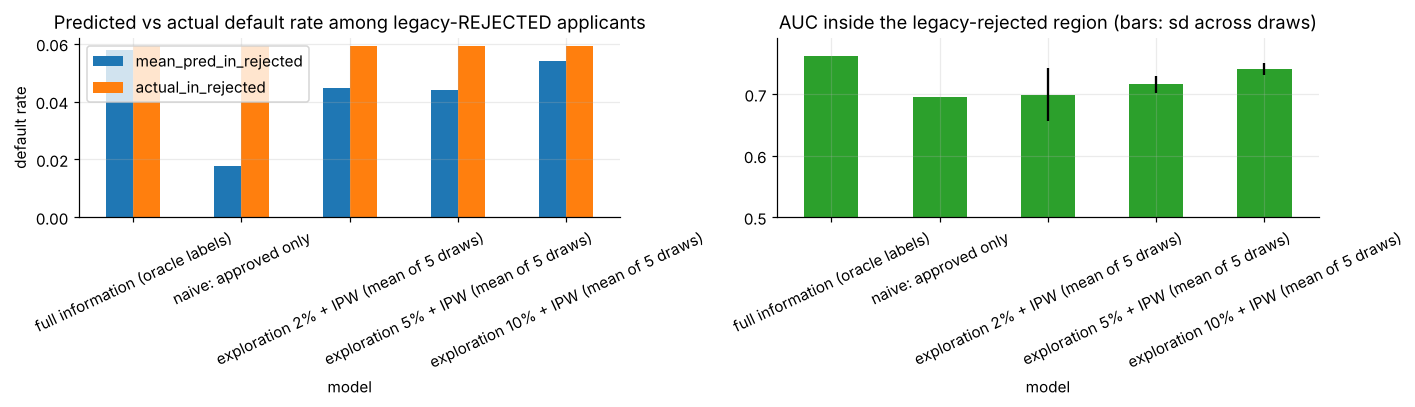

In [18]:
LEG_TR = legacy_rule(X[M["train"]]); LEG_VA = legacy_rule(X[M["valid"]])
print(f"legacy rule approves {LEG_TR.mean():.0%} of training-period applicants; default rate approved {ytr[LEG_TR].mean():.1%} vs rejected {ytr[~LEG_TR].mean():.1%}")

mt = EVAL["test normal (out-of-time)"]
Xt, yt = X[mt], A.default[mt].values; leg_t = legacy_rule(Xt); A_t = A[mt].reset_index(drop=True)
req_t = A_t.amount.values; pdt_req_t = true_pd_at(A_t, req_t, ICPT, CFG)
def cutoff_profit(p, c=0.06):
    ap = p <= c; return float((((1 - pdt_req_t) * FEE(req_t) - pdt_req_t * (1 - CFG["recovery"]) * req_t))[ap].sum())

def evaluate_variant(name, b):
    p = raw_pd(b, Xt)
    return dict(model=name, AUC_all=roc_auc_score(yt, p), AUC_in_legacy_rejected=roc_auc_score(yt[~leg_t], p[~leg_t]),
                mean_pred_in_rejected=p[~leg_t].mean(), actual_in_rejected=yt[~leg_t].mean(),
                calibration_gap_rejected=p[~leg_t].mean() - yt[~leg_t].mean(), approval_rate_at_6pct=float((p <= 0.06).mean()), profit_at_6pct_cutoff=cutoff_profit(p))

rows = [evaluate_variant("full information (oracle labels)", BOOST)]
rng_e = np.random.default_rng(5)
N_DRAWS = 5                                   # exploration is random, so repeat it and report the spread
for e in [0.0, 0.02, 0.05, 0.10]:
    draws = []
    for r in range(1 if e == 0 else N_DRAWS):
        def pick(mask_leg, n):
            if e == 0: return mask_leg, np.ones(n)
            u = rng_e.random(n) < e; return (mask_leg | u), np.where(mask_leg, 1.0, 1.0 / e)
        s_tr, w_tr = pick(LEG_TR, len(ytr)); s_va, w_va = pick(LEG_VA, len(yva))
        b = train_lgb(Xtr[s_tr], ytr[s_tr], Xva[s_va], yva[s_va], wtr=w_tr[s_tr], wva=w_va[s_va])
        draws.append(evaluate_variant("", b))
    D = pd.DataFrame(draws).drop(columns="model"); row = D.mean().to_dict()
    row["model"] = "naive: approved only" if e == 0 else f"exploration {e:.0%} + IPW (mean of {N_DRAWS} draws)"
    row["AUC_rejected_sd"] = D.AUC_in_legacy_rejected.std() if len(D) > 1 else 0.0
    row["profit_sd"] = D.profit_at_6pct_cutoff.std() if len(D) > 1 else 0.0
    rows.append(row)
SB = pd.DataFrame(rows).set_index("model").fillna(0.0); display(SB)
print(f"Note: the naive model approves {SB.loc['naive: approved only', 'approval_rate_at_6pct']:.0%} of applicants at a 6% cutoff - it cannot see risk in the region it never observed, so its profit collapses to the approve-everyone result.")
RESULTS["selection_bias"] = SB
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
SB[["mean_pred_in_rejected", "actual_in_rejected"]].plot.bar(ax=ax[0], rot=25); ax[0].set(title="Predicted vs actual default rate among legacy-REJECTED applicants", ylabel="default rate")
SB["AUC_in_legacy_rejected"].plot.bar(ax=ax[1], rot=25, color="C2"); ax[1].errorbar(range(len(SB)), SB.AUC_in_legacy_rejected, yerr=SB.AUC_rejected_sd, fmt='none', c='k'); ax[1].set(title="AUC inside the legacy-rejected region (bars: sd across draws)", ylim=(0.5, SB.AUC_in_legacy_rejected.max() + .03))
plt.tight_layout(); plt.show()

## 9. Monitoring and the stress period

The model is frozen at day 235 (start of the test window). The macro stress regime begins on day 300 (more missed paychecks, more shocks, higher underlying risk). Three monitors:

1. **Input drift (PSI)** on features and on the score. Available immediately, but it only sees movement in the *inputs*.
2. **Calibration on fully matured cohorts** (actual vs predicted default rate). Always correct, but a cohort is only fully labelled `days_to_due + 14` days after origination.
3. **Early read on fast-resolving loans**: calibration (same model, same cohort) restricted to loans whose labels have already arrived 21 days after the application week. Short-term loans resolve first, so this is a biased *sample* but an unbiased *comparison* (predictions are compared with outcomes for the same loans).

**How the stress is built, and why it matters.** The stress regime adds more missed paychecks and shocks *and* raises default risk for a given observable profile (the same balances and deposits now default more often). That last part is concept drift, `P(default | features)` moves while the features barely do. In real downturns inputs often do move; here they mostly do not, which is exactly the case where PSI-only monitoring is blind. Rule: a breach must persist two consecutive weeks (damps noise); calibration breaches must also be statistically significant (|z| > 2).

PSI rule of thumb: <0.10 stable, 0.10-0.25 watch, >0.25 act.

In [19]:
def psi(ref, cur, bins=10):
    ref = np.asarray(ref, float); cur = np.asarray(cur, float); ref, cur = ref[~np.isnan(ref)], cur[~np.isnan(cur)]
    qs = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); qs[0], qs[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, qs)[0] / len(ref), 1e-4, None); c = np.clip(np.histogram(cur, qs)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

ref = pd.concat([Xtr, Xva])      # reference = everything the model was built on (80 days, > 2 monthly bill cycles; a short window would flag normal seasonality)
rows = [{"feature": f, "PSI normal": psi(ref[f], X.loc[EVAL["test normal (out-of-time)"], f]),
         "PSI stress": psi(ref[f], X.loc[EVAL["test stress"], f])} for f in FEATURES]
PS = pd.DataFrame(rows).set_index("feature").sort_values("PSI stress", ascending=False)
sc_ref = cal_pd(BOOST, ref)
PS.loc["** SCORE **"] = [psi(sc_ref, cal_pd(BOOST, X[EVAL["test normal (out-of-time)"]])), psi(sc_ref, cal_pd(BOOST, X[EVAL["test stress"]]))]
display(PS.sort_values("PSI stress", ascending=False).head(12))

,PSI normal,PSI stress
feature,,
spend_to_income,0.002,0.052
bills_to_income,0.000,0.043
n_deposits_60,0.001,0.032
amount_to_income,0.001,0.030
est_days_to_next_dep,0.001,0.030
n_deposits_30,0.000,0.022
income_30,0.001,0.022
** SCORE **,0.002,0.020
bal_min_7,0.001,0.017


,start_day,n,pred,actual,calib_ratio,calib_z,early_n,early_ratio,early_z,score_psi,share_labeled_asof_end
week,,,,,,,,,,,
0,235,2219,0.027,0.027,0.994,-0.051,"1,240.000",0.918,-0.538,0.043,1.000
1,242,3177,0.037,0.037,1.019,0.221,"1,787.000",0.982,-0.163,0.024,1.000
2,249,3108,0.035,0.041,1.180,2.019,"1,783.000",1.003,0.032,0.008,1.000
3,256,2822,0.031,0.031,1.022,0.222,"1,660.000",1.059,0.485,0.007,1.000
4,263,2249,0.026,0.028,1.080,0.653,"1,254.000",0.978,-0.142,0.032,1.000
5,270,2842,0.034,0.040,1.192,2.024,"1,618.000",0.969,-0.266,0.015,1.000
6,277,3235,0.033,0.035,1.078,0.855,"1,874.000",1.013,0.114,0.005,1.000
7,284,2793,0.033,0.034,1.056,0.577,"1,633.000",1.035,0.296,0.004,1.000
8,291,2516,0.027,0.034,1.240,2.096,"1,434.000",1.166,1.141,0.017,1.000


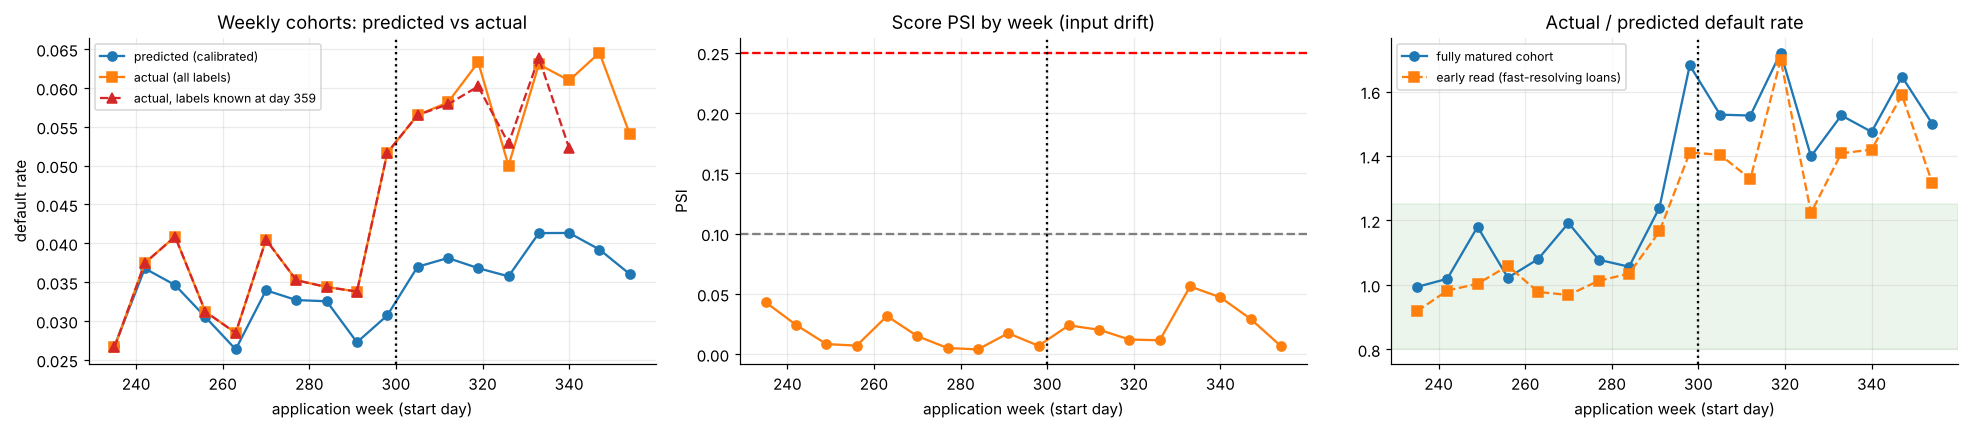

In [20]:
# weekly view over the out-of-time period
T0 = CFG["test_start"]; At = A[test].copy(); Xt_all = X[test]
At["pred"] = cal_pd(BOOST, Xt_all); At["week"] = (At.apply_day - T0) // 7
wk = At.groupby("week").agg(start_day=("apply_day", "min"), n=("app_id", "size"), pred=("pred", "mean"), actual=("default", "mean"),
                            last_label_day=("label_day", "max"), var=("pred", lambda p: float((p * (1 - p)).sum())))
wk["end_day"] = wk.start_day + 6
wk["score_psi"] = [psi(sc_ref, At.loc[At.week == w, "pred"]) for w in wk.index]
wk["calib_ratio"] = wk.actual / wk.pred
wk["calib_z"] = (wk.actual - wk.pred) * wk.n / np.sqrt(wk["var"])      # binomial z-score of actual vs predicted defaults
EARLY = 21        # days after the application week ends at which the fast-resolving-loan read is taken
def early_read(w):
    sub = At[(At.week == w) & (At.label_day <= wk.at[w, "end_day"] + EARLY)]
    p, y = sub.pred.values, sub["default"].values
    return pd.Series({"early_n": len(sub), "early_pred": p.mean(), "early_actual": y.mean(),
                      "early_z": (y.sum() - p.sum()) / np.sqrt((p * (1 - p)).sum())})
wk = wk.join(pd.DataFrame({w: early_read(w) for w in wk.index}).T)
wk["early_ratio"] = wk.early_actual / wk.early_pred
# labels known as of the last simulated day (immature cohorts look better than they are: short-term loans resolve first)
asof = CFG["n_days"] - 1
known = At[At.label_day <= asof].groupby("week")["default"].mean()
wk["actual_known_asof_end"] = known; wk["share_labeled_asof_end"] = At.assign(k=At.label_day <= asof).groupby("week")["k"].mean()
display(wk[["start_day", "n", "pred", "actual", "calib_ratio", "calib_z", "early_n", "early_ratio", "early_z", "score_psi", "share_labeled_asof_end"]])

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(wk.start_day, wk.pred, "o-", label="predicted (calibrated)"); ax[0].plot(wk.start_day, wk.actual, "s-", label="actual (all labels)")
ax[0].plot(wk.start_day, wk.actual_known_asof_end, "^--", c="C3", label=f"actual, labels known at day {asof}")
ax[0].axvline(CFG["stress_start"], c="k", ls=":"); ax[0].set(title="Weekly cohorts: predicted vs actual", xlabel="application week (start day)", ylabel="default rate"); ax[0].legend(fontsize=8)
ax[1].plot(wk.start_day, wk.score_psi, "o-", c="C1"); ax[1].axhline(.10, c="gray", ls="--"); ax[1].axhline(.25, c="r", ls="--")
ax[1].axvline(CFG["stress_start"], c="k", ls=":"); ax[1].set(title="Score PSI by week (input drift)", xlabel="application week (start day)", ylabel="PSI")
ax[2].plot(wk.start_day, wk.calib_ratio, "o-", label="fully matured cohort"); ax[2].plot(wk.start_day, wk.early_ratio, "s--", label="early read (fast-resolving loans)")
ax[2].axhspan(0.8, 1.25, color="green", alpha=.08); ax[2].axvline(CFG["stress_start"], c="k", ls=":")
ax[2].set(title="Actual / predicted default rate", xlabel="application week (start day)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [21]:
# retrain trigger: when does each monitor first fire, and when would that information be AVAILABLE?
MAX_LAG = int(A.days_to_due.max() + CFG["label_lag"])         # worst-case days until a cohort's labels have all matured
def breach(ratio, z): return ((ratio > 1.25) | (ratio < 0.80)) & (z.abs() > 2)
psi_b = wk.score_psi > 0.10
cal_b = breach(wk.calib_ratio, wk.calib_z)
early_b = breach(wk.early_ratio, wk.early_z)
def first_fire(b):
    f = b & b.shift(1, fill_value=False); return int(wk[f].end_day.iloc[0]) if f.any() else None
psi_end, cal_end, early_end = first_fire(psi_b), first_fire(cal_b), first_fire(early_b)
psi_day = psi_end
early_day = None if early_end is None else early_end + EARLY
cal_day = None if cal_end is None else cal_end + MAX_LAG
pre = wk.end_day < CFG["stress_start"]                 # weeks that finish before the stress begins
print(f"stress begins on day {CFG['stress_start']}")
print(f"false-alarm weeks before stress  -> PSI: {int(psi_b[pre].sum())}   early read: {int(early_b[pre].sum())}   matured calibration: {int(cal_b[pre].sum())}")
print(f"max weekly score PSI during stress: {wk.loc[~pre, 'score_psi'].max():.3f}   max feature PSI during stress: {PS['PSI stress'].drop('** SCORE **').max():.3f}")
fmt = lambda d: "never fired" if d is None else f"day {d}  ({d - CFG['stress_start']:+d} days after stress began)"
print(f"1. input-drift (PSI) monitor:             {fmt(psi_day)}")
print(f"2. early read, fast-resolving loans:      {fmt(early_day)}")
print(f"3. fully matured calibration monitor:     {fmt(cal_day)}")
if early_day is not None and cal_day is not None:
    print(f"=> the early read is {cal_day - early_day} days earlier than waiting for fully matured cohorts")
RESULTS["monitoring"] = dict(stress_start=CFG["stress_start"], psi_fire_day=psi_day, early_read_day=early_day, matured_calibration_day=cal_day)

stress begins on day 300
false-alarm weeks before stress  -> PSI: 0   early read: 0   matured calibration: 0
max weekly score PSI during stress: 0.056   max feature PSI during stress: 0.052
1. input-drift (PSI) monitor:             never fired
2. early read, fast-resolving loans:      day 332  (+32 days after stress began)
3. fully matured calibration monitor:     day 357  (+57 days after stress began)
=> the early read is 25 days earlier than waiting for fully matured cohorts


## 10. Do the conclusions survive different generator assumptions?

A model can look good just because it learned the author's simulator. We rerun the core pipeline (smaller population, different seed) under altered assumptions: higher base default rate, double shock frequency, more gig workers, and much noisier outcomes. The claims worth keeping are the ones that hold across rows.

In [22]:
def quick_run(overrides, n_members=8000, seed=11):
    cfg = {**CFG, **overrides, "n_members": n_members}
    S_, A_, X_, ic = generate_world(cfg, seed)
    tr, va = (A_.split == "train").values, (A_.split == "valid").values
    te = ((A_.split == "test") & (A_.regime == "normal")).values
    ytr_, yva_, yte_ = A_.default[tr].values, A_.default[va].values, A_.default[te].values
    b = train_lgb(X_[tr], ytr_, X_[va], yva_); sc = make_scorecard().fit(X_[tr], ytr_)
    leg_tr_, leg_va_, leg_te = legacy_rule(X_[tr]), legacy_rule(X_[va]), legacy_rule(X_[te])
    bn = train_lgb(X_[tr][leg_tr_], ytr_[leg_tr_], X_[va][leg_va_], yva_[leg_va_])
    p_full, p_naive = raw_pd(b, X_[te]), raw_pd(bn, X_[te])
    return dict(base_rate=yte_.mean(), oracle_AUC=roc_auc_score(yte_, A_.true_pd[te]), scorecard_AUC=roc_auc_score(yte_, sc.predict_proba(X_[te])[:, 1]),
                LGBM_AUC=roc_auc_score(yte_, p_full),
                rejected_region_AUC_full=roc_auc_score(yte_[~leg_te], p_full[~leg_te]),
                rejected_region_AUC_naive=roc_auc_score(yte_[~leg_te], p_naive[~leg_te]),
                naive_pred_vs_actual_rejected=p_naive[~leg_te].mean() / yte_[~leg_te].mean())

SCEN = {"baseline": {}, "higher default rate (8%)": {"target_base_rate": 0.08}, "2x shock frequency": {"shock_scale": 2.0},
        "50% gig workers": {"gig_share": 0.50}, "much noisier outcomes (eps sd 2.0)": {"eps_sd": 2.0}}
t0 = time.time(); ROB = pd.DataFrame({k: quick_run(v) for k, v in SCEN.items()}).T
display(ROB); print(f"done in {time.time()-t0:.0f}s")
checks = {"LightGBM AUC > scorecard AUC in every scenario": bool((ROB.LGBM_AUC > ROB.scorecard_AUC).all()),
          "naive (approved-only) model under-predicts risk in the rejected region in every scenario (ratio < 1)": bool((ROB.naive_pred_vs_actual_rejected < 1).all()),
          "full-information model beats the naive model inside the rejected region in every scenario": bool((ROB.rejected_region_AUC_full > ROB.rejected_region_AUC_naive).all())}
for k, v in checks.items(): print(("HOLDS:         " if v else "DOES NOT HOLD:") + " " + k)
RESULTS["robustness_checks"] = checks
RESULTS["robustness"] = ROB

,base_rate,oracle_AUC,scorecard_AUC,LGBM_AUC,rejected_region_AUC_full,rejected_region_AUC_naive,naive_pred_vs_actual_rejected
baseline,0.035,0.831,0.790,0.802,0.756,0.716,0.307
higher default rate (8%),0.072,0.798,0.769,0.776,0.729,0.691,0.385
2x shock frequency,0.035,0.832,0.790,0.809,0.782,0.695,0.286
50% gig workers,0.032,0.827,0.773,0.792,0.763,0.731,0.360
much noisier outcomes (eps sd 2.0),0.032,0.811,0.772,0.782,0.752,0.708,0.287


done in 15s
HOLDS:          LightGBM AUC > scorecard AUC in every scenario
HOLDS:          naive (approved-only) model under-predicts risk in the rejected region in every scenario (ratio < 1)
HOLDS:          full-information model beats the naive model inside the rejected region in every scenario


## 11. Summary, limitations, next steps

In [23]:
print("=== HEADLINE NUMBERS ===")
print("leakage test:", RESULTS["leakage_test"])
print(f"oracle AUC ceiling (test): {RESULTS['oracle_auc_test']:.3f}")
print("\nAUC by evaluation set:"); display(RESULTS["auc_table"][["scorecard", "LGBM monotone", "ORACLE (true PD)"]].loc[list(EVAL)])
print("policy comparison, normal regime (expected profit under TRUE PD):"); display(RESULTS["policy_normal"][["approval_rate", "avg_amount_approved", "exp_loss_rate", "exp_profit"]])
print("selection bias (rejected region):"); display(RESULTS["selection_bias"][["AUC_in_legacy_rejected", "mean_pred_in_rejected", "actual_in_rejected", "profit_at_6pct_cutoff"]])
print("reasons:", RESULTS["perturbation"]); print("monitoring:", RESULTS["monitoring"])

=== HEADLINE NUMBERS ===
leakage test: lag=1 changed 0 features; lag=0 changed 22
oracle AUC ceiling (test): 0.821

AUC by evaluation set:


model,scorecard,LGBM monotone,ORACLE (true PD)
set,,,
train,0.816,0.852,0.824
valid,0.792,0.807,0.831
test normal (out-of-time),0.779,0.788,0.810
"test normal, unseen members",0.736,0.761,0.785
test stress,0.782,0.792,0.817


policy comparison, normal regime (expected profit under TRUE PD):


,approval_rate,avg_amount_approved,exp_loss_rate,exp_profit
approve everyone (as requested),1.000,274.255,0.039,"66,633.618"
legacy rules (as requested),0.536,134.318,0.014,"76,309.221"
"model, fixed 6% PD cutoff",0.882,247.776,0.023,"153,314.809"
model + amount optimisation,0.988,213.062,0.023,"169,232.548"
ORACLE (true PD) + optimisation,0.987,189.631,0.018,"184,076.349"


selection bias (rejected region):


,AUC_in_legacy_rejected,mean_pred_in_rejected,actual_in_rejected,profit_at_6pct_cutoff
model,,,,
full information (oracle labels),0.761,0.058,0.059,"153,576.867"
naive: approved only,0.695,0.018,0.059,"66,633.618"
exploration 2% + IPW (mean of 5 draws),0.699,0.045,0.059,"122,256.820"
exploration 5% + IPW (mean of 5 draws),0.716,0.044,0.059,"130,537.818"
exploration 10% + IPW (mean of 5 draws),0.741,0.054,0.059,"143,843.431"


reasons: top reason beats low-ranked reason for 97% of adverse-action applicants
monitoring: {'stress_start': 300, 'psi_fire_day': None, 'early_read_day': 332, 'matured_calibration_day': 357}


**Limitations (read before quoting any number)**
- All data is synthetic. Defaults come from a hidden formula I wrote, so absolute AUCs and profits say nothing about a real lender. What transfers is the *methodology* and the *relative* comparisons (constraints vs none, naive vs exploration, input drift vs outcome monitors).
- The repayment outcome is drawn from a hidden probability, not simulated through post-advance balances.
- Fees, recovery rate and base default rate are illustrative assumptions.
- Platt calibration and early stopping share the validation set, a small optimism.
- Prior-default history features come from a world where everyone was funded; a real lender would only have them for approved applicants.

**Natural extensions**
- A real-data section on a public relational bank dataset (e.g. the Berka/PKDD'99 Czech bank data, with its well-known temporal-leakage trap) to show the same point-in-time discipline on messy data.
- A delayed-outcome A/B test of a new limit policy: early read at day 7 vs matured outcomes, with launch guardrails.
- Settlement/collections: an uplift model for who should be offered a discount.
- A fairness slice of the approval and reason-code results across synthetic demographic groups.